# 05 · Peak Fitting

How to measure each peak by fitting a line shape to it, getting center, FWHM, height, area and line shape, each with an uncertainty.

1. Fit one peak
2. Fit every detected peak
3. Check the fits against the true peaks
4. The uncertainties are honest on unsmoothed data
5. Overlapping peaks need a joint fit

Code: `src/spectro/fitting.py`.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spectro import (
    Peak,
    detect_peaks,
    estimate_noise,
    fit_peak,
    fit_peaks,
    make_spectrum,
    match_peaks,
    remove_baseline,
    smooth,
)

peaks = [
    Peak(center=3350, fwhm=300, height=0.6, shape="gaussian"),  # O–H
    Peak(center=2950, fwhm=40, height=0.4),  # C–H
    Peak(center=2870, fwhm=30, height=0.3),  # C–H
    Peak(center=1715, fwhm=25, height=0.9),  # C=O
    Peak(center=1100, fwhm=50, height=0.5, shape="lorentzian"),  # C–O
]
raw, true_peaks = make_spectrum(peaks, noise=0.01, baseline=(0.05, 0.1, -0.05), seed=3)
corrected = remove_baseline(raw)
noise = estimate_noise(corrected)
found = detect_peaks(smooth(corrected), prominence=5 * noise)

## 1. Fit One Peak

`fit_peak` starts from the detected center, FWHM and height and adjusts a pseudo-Voigt plus a straight-line background until the curve matches the data in a window of ±2 FWHM. The residual (data minus fit) should look like plain noise; any pattern in it means the shape is wrong.

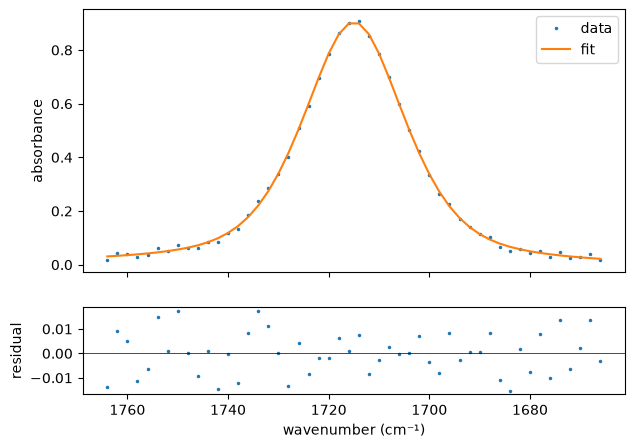

In [2]:
row = found.iloc[1]  # the C=O band near 1715 cm⁻¹
result = fit_peak(corrected, row["center"], row["fwhm"], row["height"])
x = result.userkws["x"]

fig, (top, bottom) = plt.subplots(
    2, 1, sharex=True, figsize=(7, 5), height_ratios=[3, 1]
)
top.plot(x, result.data, ".", ms=3, label="data")
top.plot(x, result.best_fit, label="fit")
top.set_ylabel("absorbance")
top.legend()
bottom.plot(x, result.residual, ".", ms=3)
bottom.axhline(0, color="k", lw=0.5)
bottom.set_ylabel("residual")
bottom.set_xlabel("wavenumber (cm⁻¹)")
bottom.invert_xaxis()
plt.show()

Each parameter comes with a standard error. `area` is computed from the others, and its error is propagated from theirs.

In [3]:
for name in ["center", "fwhm", "height", "area", "eta"]:
    p = result.params[name]
    print(f"{name:7} {p.value:9.3f} ± {p.stderr:.3f}")

center   1714.990 ± 0.056
fwhm       24.357 ± 0.186
height      0.908 ± 0.008
area       29.865 ± 0.719
eta         0.565 ± 0.044


## 2. Fit Every Detected Peak

`fit_peaks` runs `fit_peak` for each row of the detection table. Each window stops halfway to the next peak, so a fit doesn't try to describe its neighbour. Detection runs on the smoothed spectrum, but fitting runs on the unsmoothed one (part 4 shows why).

In [4]:
fitted = fit_peaks(corrected, found)
fitted.round(3)

,shape,center,center_err,fwhm,fwhm_err,height,height_err,area,area_err,eta,eta_err,rms_residual
0,pseudo_voigt,1099.958,0.173,49.086,0.732,0.502,0.006,38.726,0.995,1.000,0.030,0.010
1,pseudo_voigt,1714.990,0.056,24.357,0.186,0.908,0.008,29.865,0.719,0.565,0.044,0.009
2,pseudo_voigt,2870.030,0.225,28.980,0.740,0.267,0.011,9.215,1.224,0.247,0.199,0.009
3,pseudo_voigt,2950.483,0.221,36.880,0.763,0.358,0.011,15.119,1.555,0.159,0.141,0.009
4,pseudo_voigt,3349.383,0.776,297.266,3.108,0.589,0.009,186.482,4.784,0.000,0.005,0.010


The fitted values describe peaks completely, so they can be drawn with the same `Peak` class that made the synthetic spectrum.

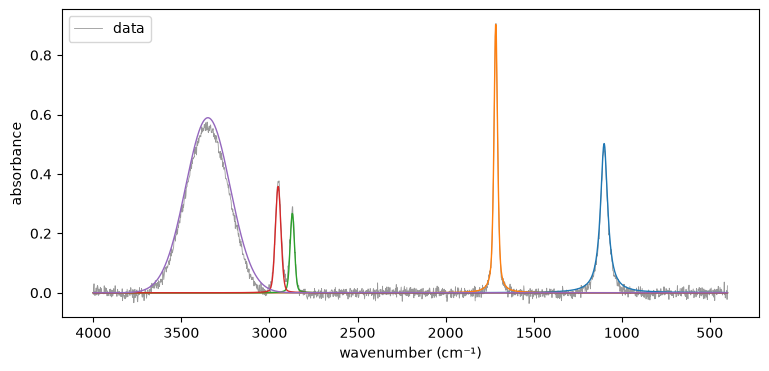

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(corrected.x, corrected.y, lw=0.6, color="0.6", label="data")
for _, p in fitted.iterrows():
    peak = Peak(p["center"], p["fwhm"], p["height"], eta=p["eta"])
    ax.plot(corrected.x, peak.evaluate(corrected.x), lw=1)
ax.set_xlabel("wavenumber (cm⁻¹)")
ax.set_ylabel("absorbance")
ax.invert_xaxis()
ax.legend(loc="upper left")
plt.show()

## 3. Check the Fits Against the True Peaks

The isolated bands (O–H, C=O, C–O) come back within a few percent in area, and η identifies their shape: 0 for the Gaussian O–H, 1 for the Lorentzian C–O, about 0.5 for the pseudo-Voigt C=O. The two C–H bands overlap, and their areas come out too small (part 5). `rms_residual` matches the noise level, so nothing is left unfitted.

In [6]:
matched = match_peaks(fitted, true_peaks, tolerance=40)
matched[
    [
        "center_true",
        "center_found",
        "area_true",
        "area_found",
        "area_err_found",
        "eta_found",
    ]
].round(2)

,center_true,center_found,area_true,area_found,area_err_found,eta_found
0,1100,1099.96,39.27,38.73,0.99,1.00
1,1715,1714.99,29.65,29.87,0.72,0.56
2,2870,2870.03,11.86,9.21,1.22,0.25
3,2950,2950.48,21.08,15.12,1.55,0.16
4,3350,3349.38,191.60,186.48,4.78,0.00


In [7]:
print(f"noise {noise:.4f}; rms residuals {fitted['rms_residual'].round(4).tolist()}")

noise 0.0101; rms residuals [0.0098, 0.0086, 0.0087, 0.0092, 0.0099]


## 4. The Uncertainties Are Honest on Unsmoothed Data

A standard error should contain the true value about 68 % of the time. Fit the same peak in 200 noisy spectra and count. On unsmoothed data it does; on smoothed data the errors are several times too small, because smoothing makes neighbouring points share their noise, and the fitted height comes out about 2 % low because smoothing flattens the peak.

In [8]:
true = Peak(1715.3, 25, 0.9)
heights = {"unsmoothed": [], "smoothed": []}
errors = {"unsmoothed": [], "smoothed": []}
for seed in range(200):
    spectrum, _ = make_spectrum([true], noise=0.01, seed=seed)
    for label, data in [("unsmoothed", spectrum), ("smoothed", smooth(spectrum))]:
        h = fit_peak(data, 1714, 22, 0.85).params["height"]
        heights[label].append(h.value)
        errors[label].append(h.stderr)

for label in heights:
    h, e = np.array(heights[label]), np.array(errors[label])
    covered = np.mean(np.abs(h - true.height) < e)
    print(
        f"{label:10}  mean height {h.mean():.3f}  spread {h.std():.4f}  "
        f"mean error {e.mean():.4f}  covers truth {covered:.0%}"
    )

unsmoothed  mean height 0.898  spread 0.0096  mean error 0.0099  covers truth 72%
smoothed    mean height 0.879  spread 0.0085  mean error 0.0034  covers truth 1%


## 5. Overlapping Peaks Need a Joint Fit

Fitting the two C–H bands one at a time, each fit sees the other band only as background, and the window is cut halfway between them, so each loses part of its area. The reported errors don't warn about this: they cover noise, not a wrong model. Step 6 fits overlapping bands together.

In [9]:
pair = matched[matched["center_true"].isin([2870, 2950])]
pair[["center_true", "area_true", "area_found", "area_err_found"]].round(2)

,center_true,area_true,area_found,area_err_found
2,2870,11.86,9.21,1.22
3,2950,21.08,15.12,1.55
